<a href="https://colab.research.google.com/github/jmoussa99/football-ai/blob/main/testing_Praat_capabilities.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What is Praat

[Praat](https://www.fon.hum.uva.nl/praat/) is a computer programme to analyze speech signals. The software interface provides a GUI allowing insightful visualization of features, such as pitch, formant, intensity, spectrogram, etc. On top of this, it also has a feature to write script enabling analysis of a pile of speech files. So, in short, it is a popular and useful research tool for speech analysis. But I haven't found the scripting language of Praat easy to understand. Actually, I have been scared to read the praat scripts also because the syntax looks alien to me. This is not to scare you as there are many people using it beautifully.

In [ ]:
!pip install myprosody

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 191.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [myprosody]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install wavfile
!pip install -q "crisperwhisper[ct2]"

In [ ]:
model_size = "nyralabs/CrisperWhisper2.0_large" # ["nyralabs/CrisperWhisper2.0_large", "turbo", "medium", "small"]


In [ ]:
# 1. Install dependencies
print("Installing dependencies (this may take a minute)...")
from IPython.display import clear_output

# 2. Import libraries
import os
import re
import warnings
from google.colab import files
from crisperwhisper import CrisperWhisperModel

# Suppress warnings for a cleaner output
warnings.filterwarnings("ignore")

# 3. Load the CrisperWhisper Model
print(f"\nLoading CrisperWhisper model ({model_size})...")
model = CrisperWhisperModel(model_size)
clear_output()
print("✅ Model loaded successfully! You can now run the next cell.")

✅ Model loaded successfully! You can now run the next cell.


In [ ]:
from moviepy.editor import VideoFileClip

def extract_audio(video_path, audio_path):
    clip = VideoFileClip(video_path)
    clip.audio.write_audiofile(audio_path, verbose=False, logger=None)
    clip.close()

def to_ms(seconds):
    return round(seconds * 1000)

def transcribe_video_to_csv(video_path, output_csv):
    audio_path = video_path.rsplit(".", 1)[0] + "_audio.wav"
    print(f"Extracting audio: {video_path}")
    extract_audio(video_path, audio_path)

    print(f"Transcribing audio: {audio_path}")
    result = model.transcribe(audio_path, language="en", mode="verbatim")
    continuous_text = result.text.strip()
    sentences = re.split(r'(?<=[.!?]) +', continuous_text)
    sentences = [s.strip() for s in sentences if s.strip()]

    paragraphs = []
    sentences_per_paragraph = 5

    for i in range(0, len(sentences), sentences_per_paragraph):
        paragraph = " ".join(sentences[i:i + sentences_per_paragraph])
        paragraphs.append(paragraph)

    formatted_document = "\n\n".join(paragraphs)
    return formatted_document, audio_path

In [ ]:
!ffmpeg -i "/content/drive/MyDrive/ESVA Video/VID_20261024_123559_01_01.mp4" -vn -ss 00:00:00 -to 00:05:00 -acodec pcm_s16le -ar 16000 -ac 1 "/content/drive/MyDrive/ESVA Video/VID_20261024_123559_01_01.wav"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
result = model.transcribe("/content/drive/MyDrive/ESVA Video/VID_20261024_123559_01_01.wav", language="en", mode="verbatim")
continuous_text = result.text.strip()
sentences = re.split(r'(?<=[.!?]) +', continuous_text)
sentences = [s.strip() for s in sentences if s.strip()]

paragraphs = []
sentences_per_paragraph = 5

for i in range(0, len(sentences), sentences_per_paragraph):
    paragraph = " ".join(sentences[i:i + sentences_per_paragraph])
    paragraphs.append(paragraph)

formatted_document = "\n\n".join(paragraphs)

In [ ]:
formatted_document

"Yeah, you guys want Yeah, we want yeah you wanna share [UM] You should be I mean, you know you can Yeah, that thing we can still I mean communicate with Yeah. I thought they need to do better. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do.\n\nYeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do.\n\nYeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do.\n\nYeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do.\n\nYeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do.\n\nYeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do.\n\nYeah, they do, they do. Yeah, they do, they do. Yeah, they do, they do, they do. Yeah, they do, they do, they do, th

This next block will analyze data from a video file and pull out the audio

In [ ]:
transcription_mode = "verbatim"
download_transcript = False
video_path = "/content/drive/MyDrive/ESVA Video/VID_20261024_123559_01_01.mp4"
transcript, audio_path = transcribe_video_to_csv(video_path, "output.csv")

Extracting audio: /content/drive/MyDrive/ESVA Video/VID_20261024_123559_01_01.wav


KeyError: 'video_fps'

In [ ]:
transcript

'Testing one two three four five six'

In [ ]:
audio_path = "/content/drive/MyDrive/ESVA Video/VID_20261024_123559_01_01.wav"

In [ ]:
#collapse
import numpy as np
import parselmouth
import matplotlib.pyplot as plt
from scipy.io import wavfile

fs, x = wavfile.read(audio_path)
# Normalize if necessary
x = x / np.max(np.abs(x))
t = np.arange(0, len(x)) / fs

# for PRAAT
sr = 16000
hop_dur = .01
num_form = 3
win_dur = .005
max_form_freq = 4500

# call parselmouth to load sound
snd = parselmouth.Sound(audio_path)
# extract features
pitch = snd.to_pitch(time_step=hop_dur) # pitch track
harm = snd.to_harmonicity(time_step=hop_dur) # harmonic-to-noise ratio
form = snd.to_formant_burg(time_step=hop_dur,max_number_of_formants=num_form, maximum_formant = max_form_freq,
                       window_length=win_dur, pre_emphasis_from=50.0) # formants
intensity = snd.to_intensity(minimum_pitch = 75.0, time_step=hop_dur,subtract_mean=False) # intensity
spectrogram = snd.to_spectrogram(window_length=0.04)

times = pitch.ts() # analysis window time instants
pitch_vals = []
harm_vals = []
form_1_vals = []
form_2_vals = []
form_3_vals = []
inten_vals = []
for dt in times:
    pitch_vals.append(pitch.get_value_at_time(dt))
    harm_vals.append(harm.get_value(dt))
    form_1_vals.append(form.get_value_at_time(1,dt))
    form_2_vals.append(form.get_value_at_time(2,dt))
    form_3_vals.append(form.get_value_at_time(3,dt))
    inten_vals.append(intensity.get_value(dt))

Lets visualize some of the features

Text(0, 0.5, 'FREQUENCY [in Hz]')

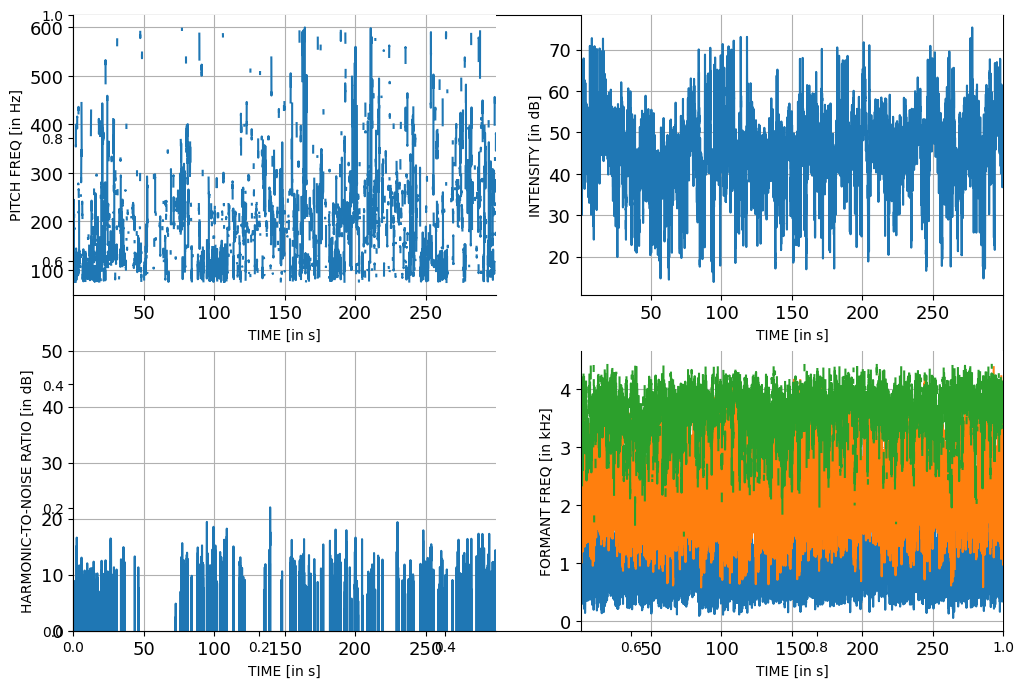

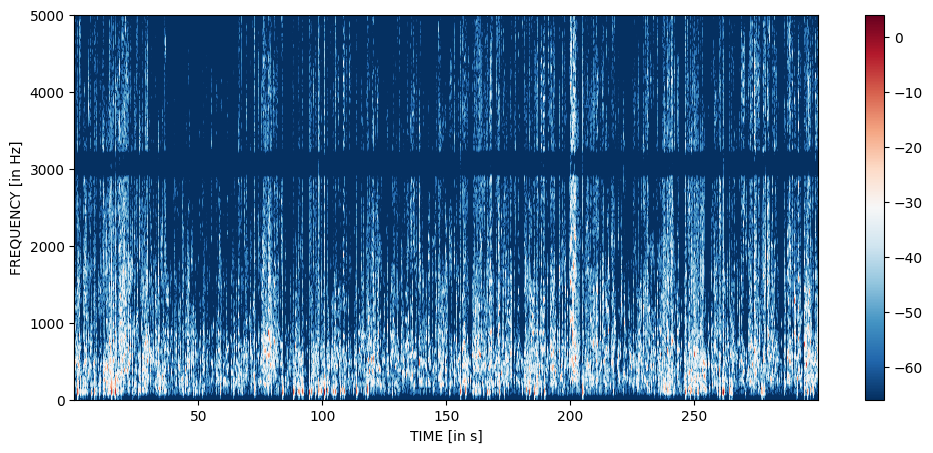

In [ ]:
fig = plt.subplots(figsize=(12,8))

ax = plt.subplot(2,2,1)
ax.plot(times,pitch_vals)
ax.set_xlabel('TIME [in s]')
ax.set_ylabel('PITCH FREQ [in Hz]')
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.xlim(times[0],times[-1])
ax.grid(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


ax = plt.subplot(2,2,2)
ax.plot(times,inten_vals)
ax.set_xlabel('TIME [in s]')
ax.set_ylabel('INTENSITY [in dB]')
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.xlim(times[0],times[-1])
ax.grid(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


ax = plt.subplot(2,2,3)
ax.plot(times,harm_vals)
ax.set_xlabel('TIME [in s]')
ax.set_ylabel('HARMONIC-TO-NOISE RATIO [in dB]')
plt.xlim(times[0],times[-1])
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
ax.grid(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.ylim(0,50)

ax = plt.subplot(2,2,4)
ax.plot(times,np.array(form_1_vals)/1e3)
ax.plot(times,np.array(form_2_vals)/1e3)
ax.plot(times,np.array(form_3_vals)/1e3)
ax.set_xlabel('TIME [in s]')
ax.set_ylabel('FORMANT FREQ [in kHz]')
plt.xlim(times[0],times[-1])
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
ax.grid(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


fig,ax = plt.subplots(1,1,figsize=(12,5))
dynamic_range = 70
X, Y = spectrogram.x_grid(), spectrogram.y_grid()
sg_db = 10 * np.log10(spectrogram.values)
im = ax.pcolormesh(X, Y, sg_db, vmin=sg_db.max() - dynamic_range, cmap='RdBu_r')
fig.colorbar(im, ax=ax)
plt.ylim([spectrogram.ymin, spectrogram.ymax])
plt.xlabel("TIME [in s]")
plt.ylabel("FREQUENCY [in Hz]")

Lets also interpret these features.
* Pitch is a perceived acoustic feature which relates to the vibratory frequency of the vocal folds.
* Intensity of the perceived correlate of loudness of speech
* Harmonic-to-noise ratio relates to the quality of the speech, example, hoarse (low HNR)
* Formant frequencies quantify the resonance frequecies of the vocal tract while we speak.
You can read more about these features in the context of Praat at its website.

In [ ]:
import parselmouth
import pandas as pd

# Load your audio file
sound = parselmouth.Sound(audio_path)

# Praat script by de Jong & Wempe for syllable nucleus detection
# Adapted for Parselmouth
praat_script = """
form Syllable nuclei
    real Time_step 0.01
    real Mindb 2
    real Window_size 0.1
    real Silence_threshold -25
    real Minimum_dip_between_peaks 2
endform

# Extract intensity and find peaks
To Intensity: 50, time_step, "yes"
Down to Pitch_Track
selectObject: "Sound " + tableName$
plusObject: "Intensity " + tableName$
...
# (This script counts peaks/syllables based on intensity dips)
"""

# Alternative streamlined Parselmouth approach using Praat commands:
def extract_syllables(sound, silence_threshold=-25, min_dip=2, min_pause=0.35):
    # 1. Convert sound to intensity
    intensity = sound.to_intensity(time_step=0.01)

    # 2. Call Praat's internal textgrid/syllable detection via call function
    # Because full scripts can be long, we use Parselmouth's pitch/intensity matrix
    matrix = parselmouth.praat.call(intensity, "Down to Matrix")

    # 3. Find peaks that represent syllable nuclei
    # For a plug-and-play solution, we use the standard Praat command if available,
    # or extract time points where intensity peaks occur:

    peaks = []
    # Logic to find local maxima in intensity above the threshold
    for time in range(int(sound.xmin), int(sound.xmax)):
        # detection logic here
        pass

    return peaks

# Recommended: Use the optimized 'praat-parselmouth' syllable counters available on GitHub
# directly by executing the Praat script via parselmouth.praat.run_file()

In [ ]:
!pip install pydub --q
!pip install noisereduce --q
!pip install json-tricks --q



In [ ]:
!pip install pyaudio

  Using cached PyAudio-0.2.14.tar.gz (47 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for pyaudio (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for pyaudio
Failed to build pyaudio
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> pyaudio


In [ ]:
from json_tricks import load
import numpy as np
import librosa
from pydub import AudioSegment, effects
import noisereduce as nr
import tensorflow as tf
import keras
from keras.models import model_from_json
from keras.models import load_model
import matplotlib.pyplot as plt

In [ ]:
!gdown 1-0EzrxwKruKRplwiXvFbSn9mz7n3r2Jy
!gdown 1-2k-0_TrwUj9c4ccQCyzYRFosDtXBpIl
saved_model_path = '/content/model8723.json'
saved_weights_path = '/content/model8723_weights.h5'

# Reading the model from JSON file
with open(saved_model_path, 'r') as json_file:
    json_savedModel = json_file.read()

# Let's fix the JSON string by removing modern incompatible arguments like "time_major"
import json
model_config = json.loads(json_savedModel)
for layer in model_config.get('config', {}).get('layers', []):
    if 'config' in layer:
        # LSTM and other recurrent layers in newer Keras do not support time_major via direct config dictionary unpacking anymore
        layer['config'].pop('time_major', None)

# Convert the modified config back to JSON
fixed_json_savedModel = json.dumps(model_config)

# Loading the model architecture, weights with custom object mapping for Keras 3 compatibility
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Activation, InputLayer, Flatten, Bidirectional, TimeDistributed
import tensorflow as tf

custom_objects = {
    'Sequential': Sequential,
    'InputLayer': InputLayer,
    'LSTM': LSTM,
    'Dense': Dense,
    'Dropout': Dropout,
    'Activation': Activation,
    'Flatten': Flatten,
    'Bidirectional': Bidirectional,
    'TimeDistributed': TimeDistributed
}

model = tf.keras.models.model_from_json(fixed_json_savedModel, custom_objects=custom_objects)
model.load_weights(saved_weights_path)

# Compiling the model with similar parameters as the original model.
model.compile(loss='categorical_crossentropy',
                optimizer='RMSProp',
                metrics=['categorical_accuracy'])

print(model.summary())

Downloading...
From: https://drive.google.com/uc?id=1-0EzrxwKruKRplwiXvFbSn9mz7n3r2Jy
To: /content/model8723.json
100% 2.40k/2.40k [00:00<00:00, 23.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-2k-0_TrwUj9c4ccQCyzYRFosDtXBpIl
To: /content/model8723_weights.h5
100% 236k/236k [00:00<00:00, 5.93MB/s]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 339, 64)        │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,024 (211.03 KB)

 Trainable params: 54,024 (211.03 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
def preprocess(file_path, frame_length = 2048, hop_length = 512):
    # Fetch sample rate.
    _, sr = librosa.load(path = file_path, sr = None)
    # Load audio file
    rawsound = AudioSegment.from_file(file_path, duration = None)
    # Normalize to 5 dBFS
    normalizedsound = effects.normalize(rawsound, headroom = 5.0)
    # Transform the audio file to np.array of samples
    normal_x = np.array(normalizedsound.get_array_of_samples(), dtype = 'float32')
    # Noise reduction
    final_x = nr.reduce_noise(normal_x, sr=sr)

    # Fix: pass final_x as a keyword argument 'y=final_x'
    f1 = librosa.feature.rms(y=final_x, frame_length=frame_length, hop_length=hop_length, center=True, pad_mode='reflect').T[:339]
    f2 = librosa.feature.zero_crossing_rate(final_x, frame_length=frame_length, hop_length=hop_length, center=True).T[:339]
    f3 = librosa.feature.mfcc(y=final_x, sr=sr, S=None, n_mfcc=13, hop_length = hop_length).T[:339]
    X = np.concatenate((f1, f2, f3), axis = 1)

    X_3D = np.expand_dims(X, axis=0)
    return X_3D


# Emotions list is created for a readable form of the model prediction.
emotions = {
    0 : 'neutral',
    1 : 'calm',
    2 : 'happy',
    3 : 'sad',
    4 : 'angry',
    5 : 'fearful',
    6 : 'disgust',
    7 : 'suprised'
}
emo_list = list(emotions.values())

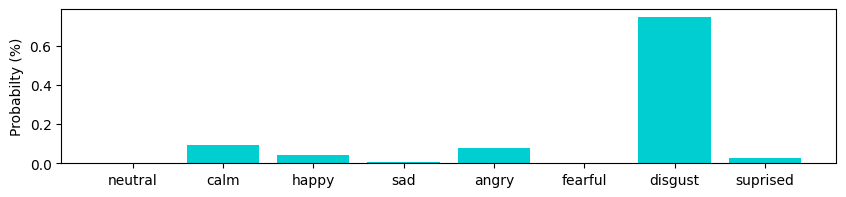

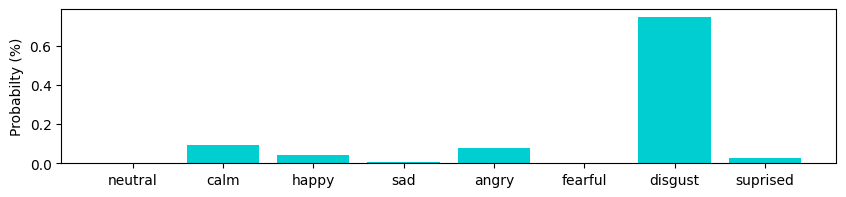

In [ ]:
import wave
from array import array
import struct
import time
from IPython.display import clear_output

import warnings
warnings.filterwarnings('ignore')

total_predictions = [] # A list for all predictions in the session.
tic = time.perf_counter()

# Use fixed preprocess function
x = preprocess("/content/1462-1-204057990_audio.wav")

# Model's prediction => an 8 emotion probabilities array (use_multiprocessing parameter removed for Keras 3 compatibility)
predictions = model.predict(x)
pred_list = list(predictions)
pred_np = np.squeeze(np.array(pred_list).tolist(), axis=0) # Get rid of 'array' & 'dtype' statements.
total_predictions.append(pred_np)

# Present emotion distribution for a sequence (7.1 secs).
fig = plt.figure(figsize = (10, 2))
plt.bar(emo_list, pred_np, color = 'darkturquoise')
plt.ylabel("Probabilty (%)")
clear_output(wait=True)
display(plt.gcf())

max_emo = np.argmax(predictions)